In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
FROZEN_EPOCHS = 8
FINE_TUNE_EPOCHS = 5

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
BASE_DIR = (
    '/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/'
    'New Plant Diseases Dataset(Augmented)/'
    'New Plant Diseases Dataset(Augmented)'
)
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VALID_DIR = os.path.join(BASE_DIR, 'valid')

assert os.path.exists(TRAIN_DIR), 'Training directory was not found.'
assert os.path.exists(VALID_DIR), 'Validation directory was not found.'

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels='inferred', label_mode='int',
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED
)
valid_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR, labels='inferred', label_mode='int',
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
assert class_names == valid_ds.class_names, 'Training and validation class names differ.'
print(f'Classes: {num_classes}')
print(class_names[:10])

Found 70295 files belonging to 38 classes.


I0000 00:00:1783945656.850419      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783945656.853649      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 17572 files belonging to 38 classes.
Classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']


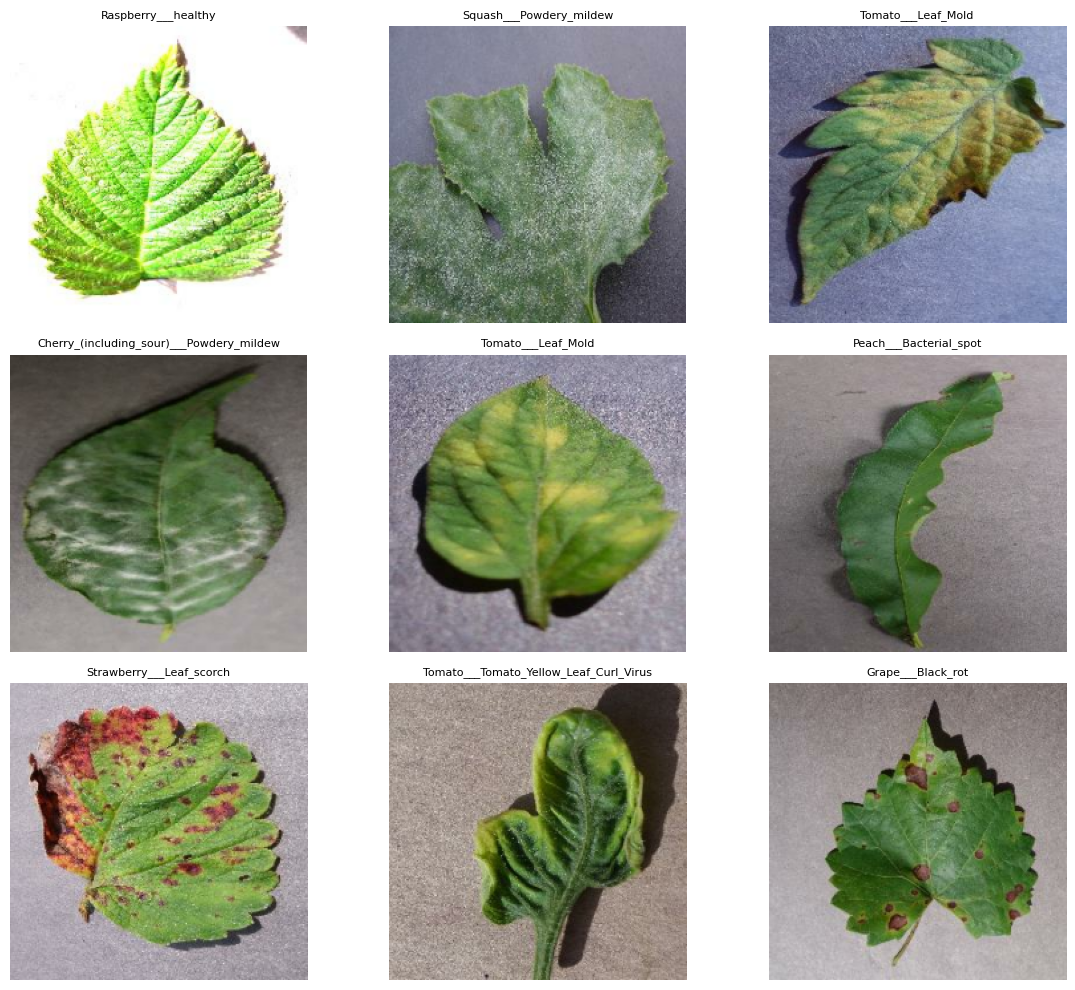

In [3]:
plt.figure(figsize=(12, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]], fontsize=8)
        plt.axis('off')
plt.tight_layout()
plt.show()

AUTOTUNE = tf.data.AUTOTUNE
train_data = train_ds.prefetch(AUTOTUNE)
valid_data = valid_ds.prefetch(AUTOTUNE)

In [4]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name='data_augmentation')

base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='leaf_image')
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
x = layers.BatchNormalization(name='classifier_batch_norm')(x)
x = layers.Dense(
    256, activation='relu', kernel_regularizer=regularizers.l2(1e-4),
    name='dense_256'
)(x)
x = layers.Dropout(0.30, name='dropout')(x)
outputs = layers.Dense(num_classes, activation='softmax', name='disease_prediction')(x)

model = keras.Model(inputs, outputs, name='plant_disease_efficientnetb0_frozen')
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "plant_disease_efficientnetb0_frozen"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_batch_norm           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_prediction (Dense)      │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,392,393 (16.76 MB)

 Trainable params: 340,262 (1.30 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [5]:
FROZEN_BEST_PATH = '/kaggle/working/efficientnetb0_frozen_best.keras'
FROZEN_LAST_PATH = '/kaggle/working/efficientnetb0_frozen_last.keras'
CLASS_NAMES_PATH = '/kaggle/working/efficientnetb0_class_names.json'

with open(CLASS_NAMES_PATH, 'w') as file:
    json.dump(class_names, file, indent=2)

frozen_callbacks = [
    ModelCheckpoint(FROZEN_BEST_PATH, monitor='val_accuracy', mode='max', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', mode='max', patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1),
    CSVLogger('/kaggle/working/efficientnetb0_frozen_log.csv')
]

history_frozen = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=FROZEN_EPOCHS,
    callbacks=frozen_callbacks
)
model.save(FROZEN_LAST_PATH)

Epoch 1/8


E0000 00:00:1783945681.255769      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/plant_disease_efficientnetb0_frozen_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.8144 - loss: 0.6890
Epoch 1: val_accuracy improved from None to 0.95385, saving model to /kaggle/working/efficientnetb0_frozen_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb0_frozen_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 212s 90ms/step - accuracy: 0.8844 - loss: 0.4332 - val_accuracy: 0.9538 - val_loss: 0.2146 - learning_rate: 0.0010
Epoch 2/8
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9337 - loss: 0.2946
Epoch 2: val_accuracy improved from 0.95385 to 0.96483, saving model to /kaggle/working/efficientnetb0_frozen_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb0_frozen_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 196s 89ms/step - accuracy: 0.9334 - loss: 0.2983 - val_accuracy: 0.9648 - val_loss: 0.2066 - learning_rate: 0.0010
Epoch 3/8
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9399 - loss: 0.2905
Epoch 3: val_accuracy improved from 0.96483 to 

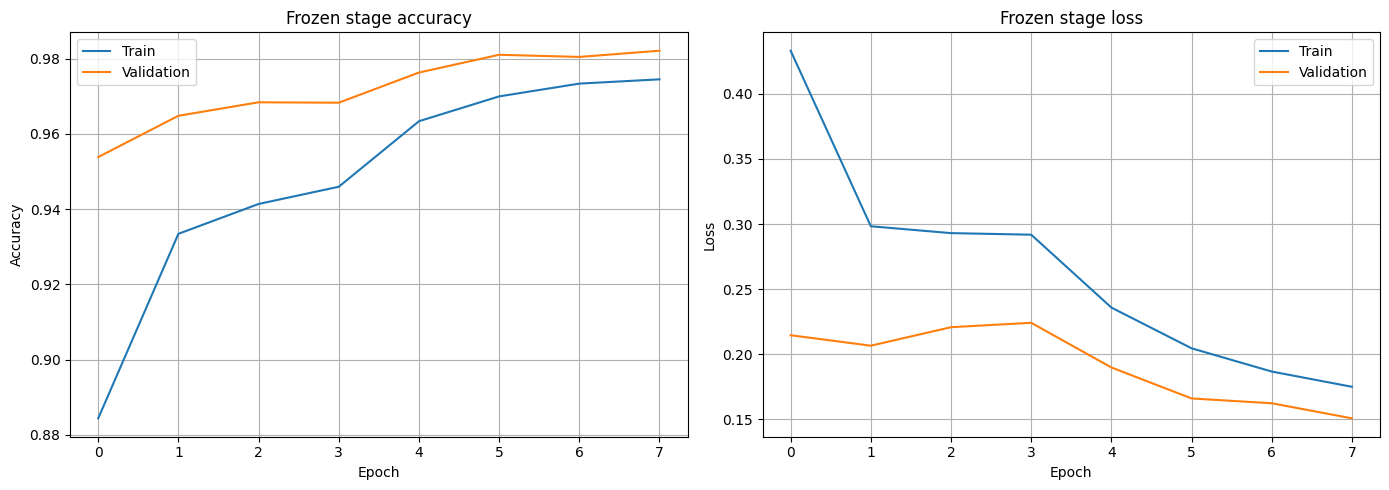

In [6]:
history_df = pd.DataFrame(history_frozen.history)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_df['accuracy'], label='Train')
plt.plot(history_df['val_accuracy'], label='Validation')
plt.title('Frozen stage accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()
plt.subplot(1, 2, 2)
plt.plot(history_df['loss'], label='Train')
plt.plot(history_df['val_loss'], label='Validation')
plt.title('Frozen stage loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid()
plt.tight_layout(); plt.show()

In [7]:
fine_tune_model = keras.models.load_model(FROZEN_BEST_PATH)
base_model = fine_tune_model.get_layer('efficientnetb0')
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization fixed for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

fine_tune_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

FINE_TUNED_PATH = '/kaggle/working/efficientnetb0_finetuned_best.keras'
fine_tune_callbacks = [
    ModelCheckpoint(FINE_TUNED_PATH, monitor='val_accuracy', mode='max', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', mode='max', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1),
    CSVLogger('/kaggle/working/efficientnetb0_finetuned_log.csv')
]

history_finetuned = fine_tune_model.fit(
    train_data,
    validation_data=valid_data,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks
)

Epoch 1/5


E0000 00:00:1783947420.277452      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/plant_disease_efficientnetb0_frozen_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9774 - loss: 0.1618
Epoch 1: val_accuracy improved from None to 0.98560, saving model to /kaggle/working/efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb0_finetuned_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 231s 99ms/step - accuracy: 0.9794 - loss: 0.1567 - val_accuracy: 0.9856 - val_loss: 0.1386 - learning_rate: 1.0000e-05
Epoch 2/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9828 - loss: 0.1461
Epoch 2: val_accuracy improved from 0.98560 to 0.98725, saving model to /kaggle/working/efficientnetb0_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb0_finetuned_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 217s 99ms/step - accuracy: 0.9835 - loss: 0.1444 - val_accuracy: 0.9873 - val_loss: 0.1346 - learning_rate: 1.0000e-05
Epoch 3/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9836 - loss: 0.1416
Epoch 3: val_accuracy did n

In [8]:
final_model = keras.models.load_model(FINE_TUNED_PATH)
validation_loss, validation_accuracy = final_model.evaluate(valid_data, verbose=1)
print(f'Final validation loss: {validation_loss:.4f}')
print(f'Final validation accuracy: {validation_accuracy:.2%}')

y_true = np.concatenate([labels.numpy() for _, labels in valid_data])
probabilities = final_model.predict(valid_data, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_true, y_pred, labels=np.arange(num_classes),
    target_names=class_names, zero_division=0
))

550/550 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.9900 - loss: 0.1258
Final validation loss: 0.1258
Final validation accuracy: 99.00%
550/550 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.98      0.99       504
                                 Apple___Black_rot       1.00      1.00      1.00       497
                          Apple___Cedar_apple_rust       1.00      0.99      0.99       440
                                   Apple___healthy       0.97      1.00      0.99       502
                               Blueberry___healthy       1.00      1.00      1.00       454
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       421
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.98      0.93      0.

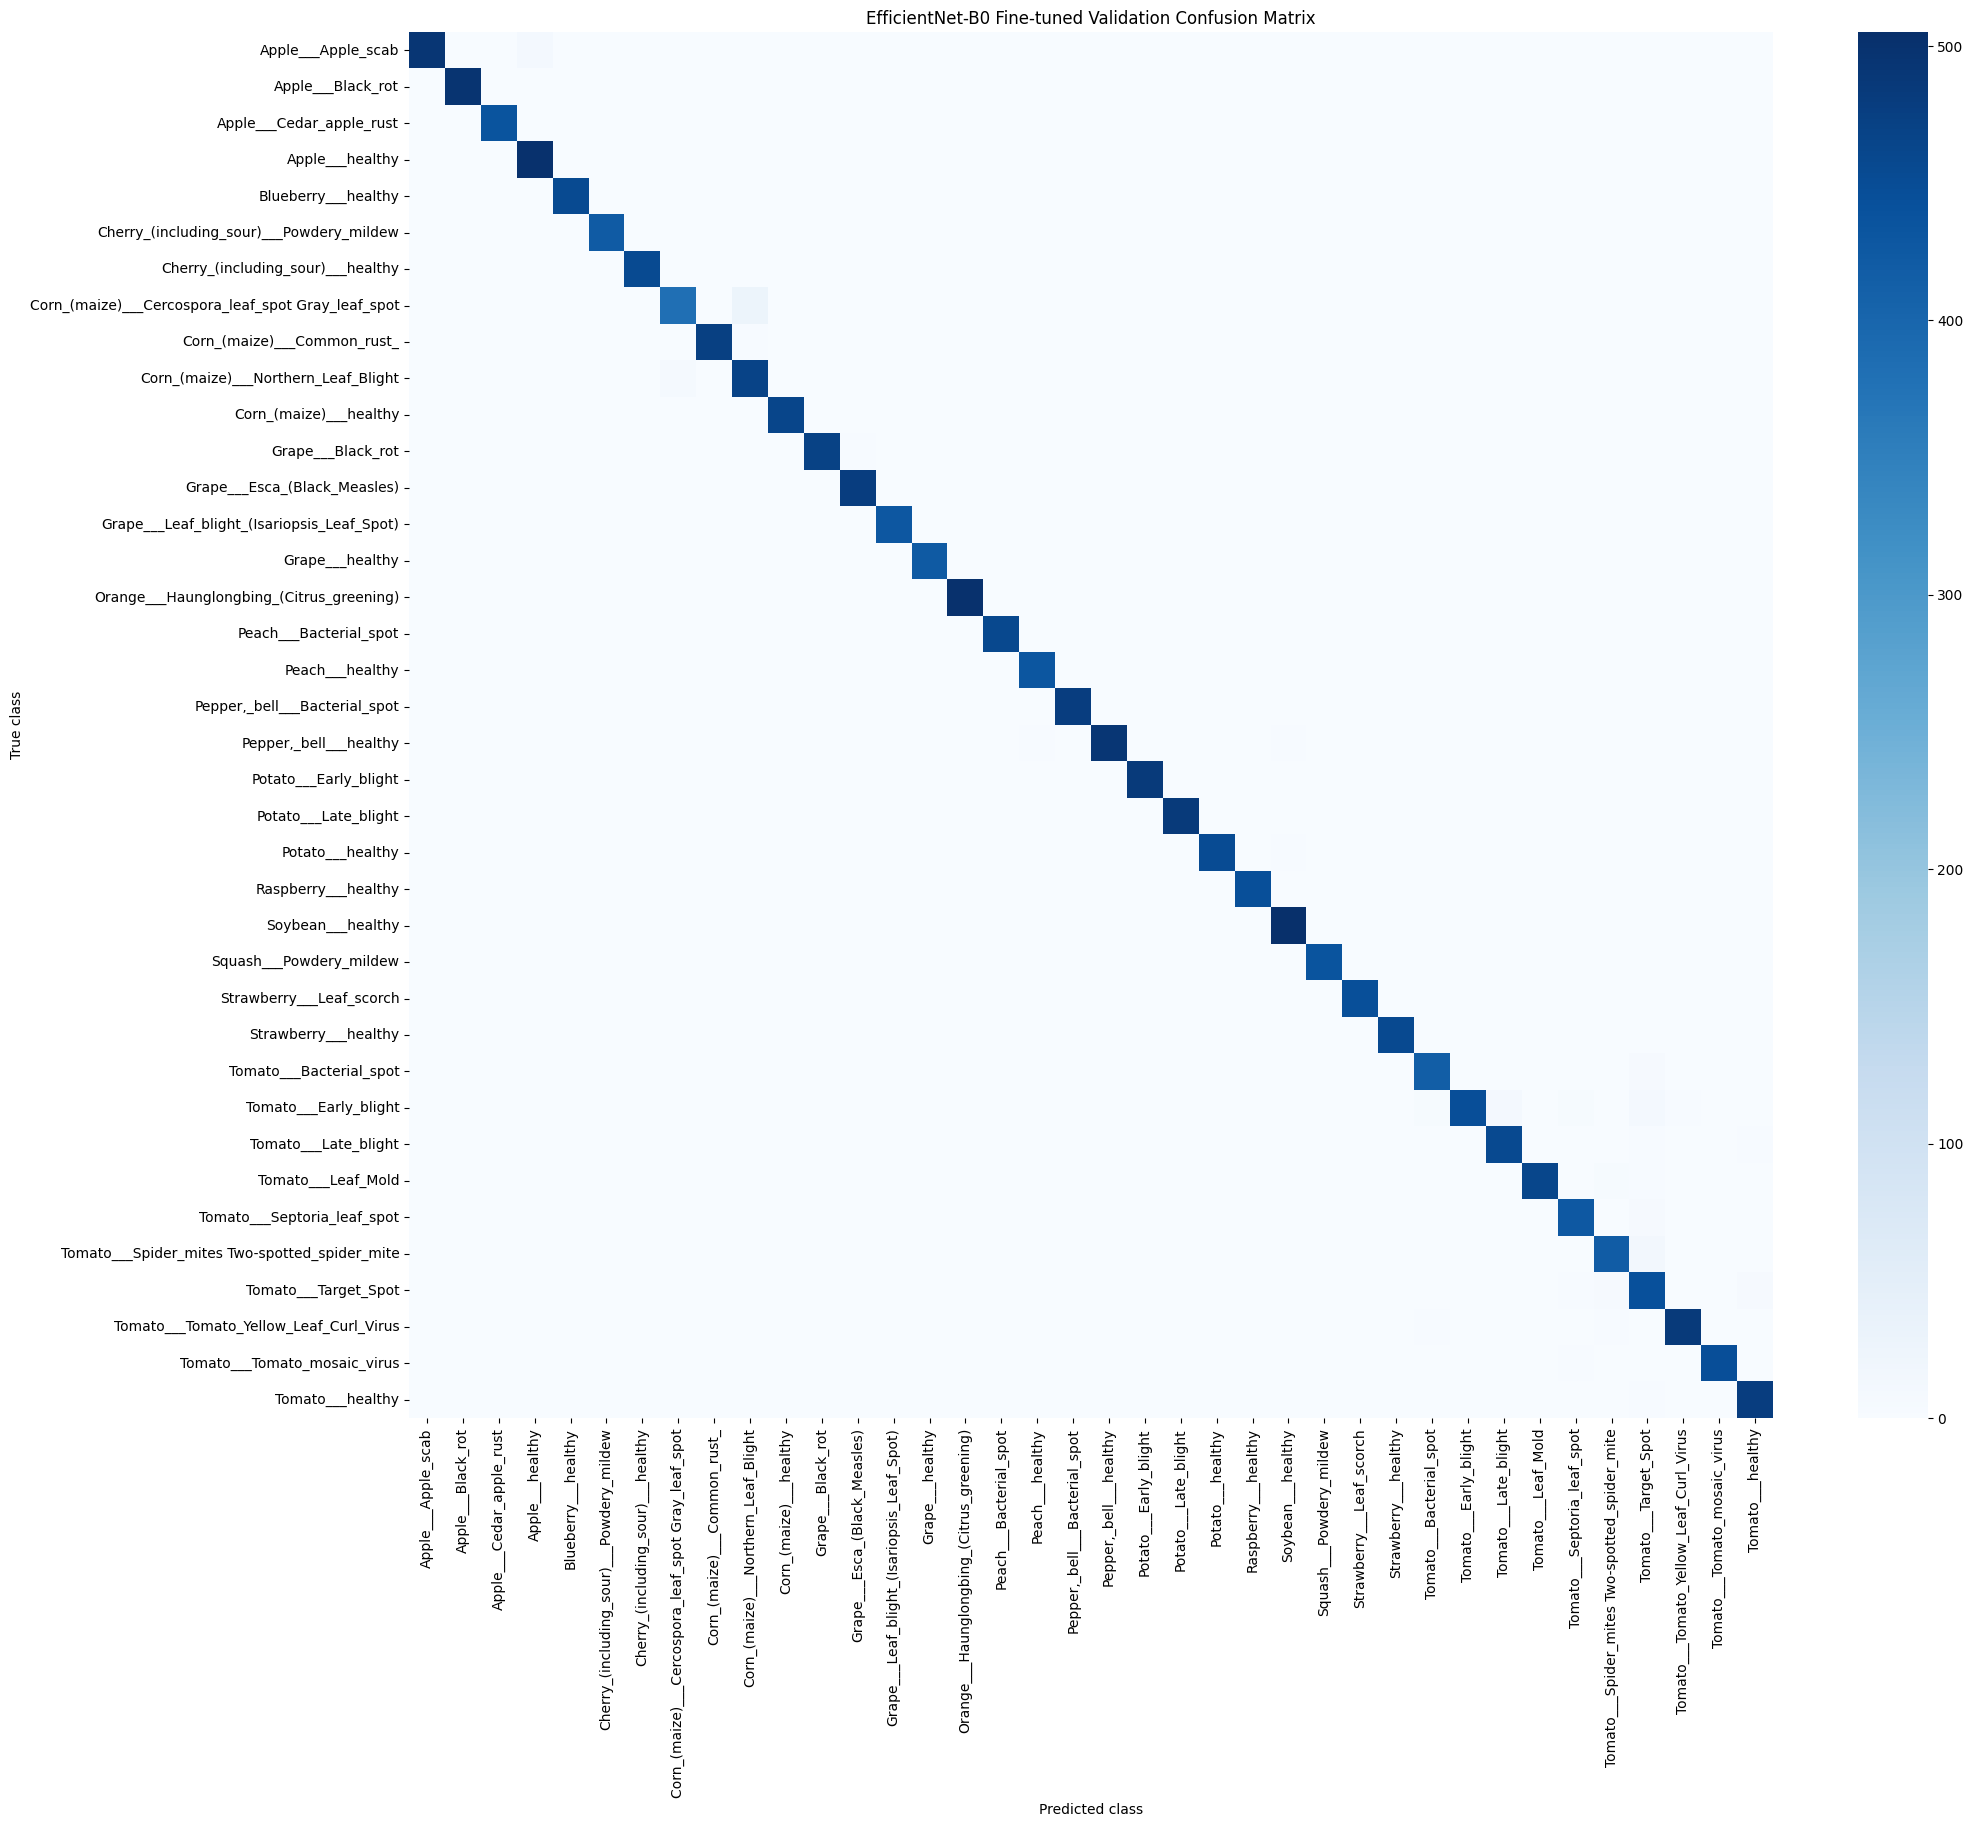

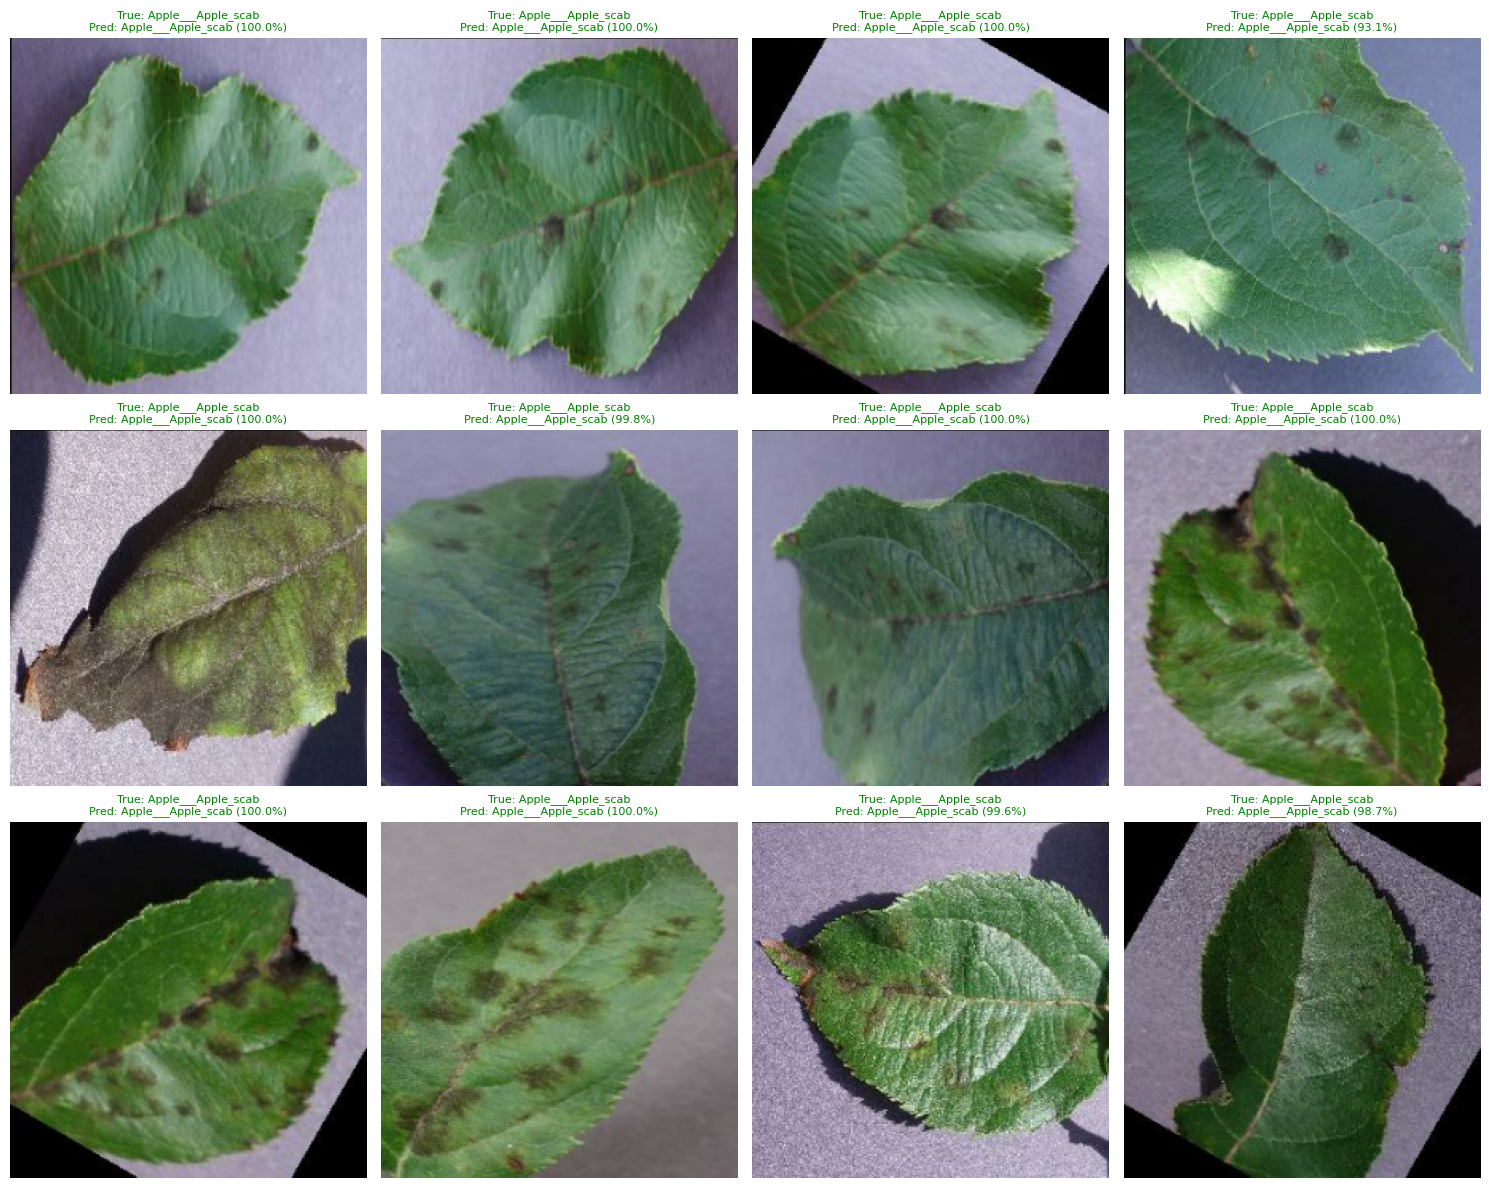

In [9]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(22, 18))
sns.heatmap(cm, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('EfficientNet-B0 Fine-tuned Validation Confusion Matrix')
plt.xlabel('Predicted class'); plt.ylabel('True class')
plt.show()

images, labels = next(iter(valid_data))
batch_probabilities = final_model.predict(images, verbose=0)
batch_predictions = np.argmax(batch_probabilities, axis=1)

plt.figure(figsize=(15, 12))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().astype('uint8'))
    true_name = class_names[labels[i]]
    predicted_name = class_names[batch_predictions[i]]
    confidence = batch_probabilities[i, batch_predictions[i]] * 100
    color = 'green' if labels[i] == batch_predictions[i] else 'red'
    plt.title(f'True: {true_name}\nPred: {predicted_name} ({confidence:.1f}%)', color=color, fontsize=8)
    plt.axis('off')
plt.tight_layout(); plt.show()

In [10]:
 MODEL_NAME = "EfficientNetB0"
 MODEL_PATH = "/kaggle/working/efficientnetb0_finetuned_best.keras"

# Evaluate final model
final_model = keras.models.load_model(MODEL_PATH)
val_loss, val_accuracy = final_model.evaluate(valid_data, verbose=0)


In [12]:
import time
# Measure inference speed on one batch
sample_images, _ = next(iter(valid_data))

start_time = time.time()
_ = final_model.predict(sample_images, verbose=0)
inference_time = time.time() - start_time

metrics = {
    "model_name": MODEL_NAME,
    "validation_accuracy": float(val_accuracy),
    "validation_loss": float(val_loss),
    "total_parameters": int(final_model.count_params()),
    "model_size_mb": round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2),
    "batch_size": BATCH_SIZE,
    "batch_inference_seconds": round(inference_time, 4),
    "seconds_per_image": round(inference_time / len(sample_images), 5)
}

print(json.dumps(metrics, indent=2))

with open(f"/kaggle/working/{MODEL_NAME}_metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

{
  "model_name": "EfficientNetB0",
  "validation_accuracy": 0.9899840950965881,
  "validation_loss": 0.12583321332931519,
  "total_parameters": 4392393,
  "model_size_mb": 31.5,
  "batch_size": 32,
  "batch_inference_seconds": 2.2062,
  "seconds_per_image": 0.06894
}
